# Linear algebra 1: Vectors and matrices

*Learning path: linear algebra, part 1 of 2.* [Index](README.md) · Next: [Eigenvalues](02-eigenvalues.ipynb)

Linear algebra is the mathematics of arrows and of the transformations that keep straight lines straight. It runs
computer graphics, search engines, machine learning and quantum mechanics. In this lesson you will learn

* vectors: adding, scaling, length, the **dot product** and angles,
* a matrix as a **transformation** of the plane, and what its columns mean,
* multiplying matrices = doing one transformation after another,
* the **determinant**: how much a matrix scales areas,
* solving systems of linear equations, and what row reduction, rank and the null space tell you.

You need the [foundations](../foundations/README.md) up to trigonometry.

## 1. Vectors

A vector in the plane is an arrow, written as its two components: $u = [3\ 4]$ goes 3 to the right and 4 up. Vectors
are added component by component (put the arrows head to tail) and multiplied by numbers (stretch the arrow):

In [1]:
u = [3 4];
v = [4 -2];
u + v
2*u
u - v

7	2
6	8
-1	6

The plot draws $u$, $v$ and $u + v$ as arrows from the origin. Each arrow is a straight segment
`parametric(s*a, s*b, s, 0, 1)`: the points $s\cdot[a\ b]$ for $s$ from 0 to 1. The axes are the two components.

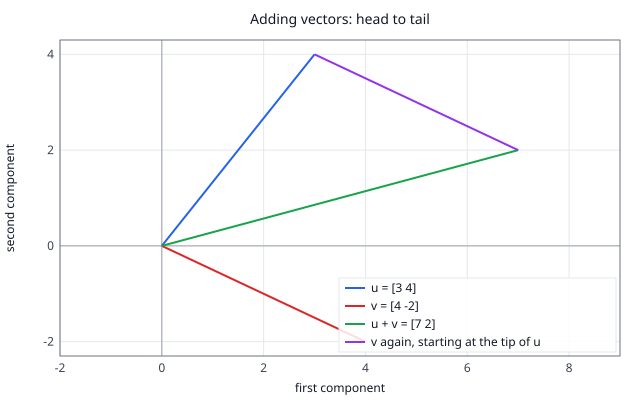

In [2]:
p = show(parametric(3*s, 4*s, s, 0, 1), parametric(4*s, -2*s, s, 0, 1), parametric(7*s, 2*s, s, 0, 1), parametric(3 + 4*s, 4 - 2*s, s, 0, 1));
p = legend(p, "u = [3 4]", "v = [4 -2]", "u + v = [7 2]", "v again, starting at the tip of u");
labels(title(p, "Adding vectors: head to tail"), "first component", "second component")

### Length, dot product and angle

The **length** of $[a\ b]$ is $\sqrt{a^2 + b^2}$ (Pythagoras), computed by `norm`. The **dot product** multiplies
matching components and adds: $u\cdot v = u_1v_1 + u_2v_2$. It measures how much two arrows point the same way:

$$u \cdot v = |u|\,|v|\cos\theta,$$

where $\theta$ is the angle between them. So $\cos\theta = \dfrac{u\cdot v}{|u|\,|v|}$, and a dot product of 0 means
the arrows are **perpendicular**:

In [3]:
norm(u)
dot(u, v)
dot(u, [4 -3])
acos(dot([1 0], [1 1])/(norm([1 0])*norm([1 1])))
eval(acos(dot(u, v)/(norm(u)*norm(v)))*180/pi)

5
4
0

pi/4

79.69515353123397

$[3\ 4]$ and $[4\ {-3}]$ are perpendicular, $[1\ 0]$ and $[1\ 1]$ make an angle of $\pi/4 = 45^\circ$, and $u$ and $v$
make an angle of about $79.7^\circ$. Everything works the same in three dimensions (or a thousand) with more components;
`cross(a, b)` gives a vector perpendicular to two vectors in 3D:

In [4]:
cross([1 0 0], [0 1 0])

0	0	1

## 2. Matrices transform the plane

A $2\times2$ matrix $A$ turns a vector $x$ (written as a column) into another vector $Ax$: each component of $Ax$ is
the dot product of a row of $A$ with $x$.

In [5]:
A = [2 1; 1 2];
A*[1; 0]
A*[0; 1]
A*[1; 1]

2
1
1
2
3
3

The images of $[1\ 0]$ and $[0\ 1]$ are the **columns** of $A$. That is all you need to know about a linear
transformation: since $x = x_1[1\ 0] + x_2[0\ 1]$, its image is $x_1\cdot(\text{column 1}) + x_2\cdot(\text{column 2})$.

To see what $A$ does to the whole plane, look at what it does to the unit circle, the points $[\cos t\ \sin t]$. `w`
is the image of the circle point at angle $t$; `w(1)` and `w(2)` are its two components:

In [6]:
w = A*[cos(t); sin(t)]

sin(t)+2*cos(t)
2*sin(t)+cos(t)

The plot shows the unit circle (blue) and its image, an ellipse (red), with the images of the two unit arrows. Axes:
the two coordinates of the plane. `parametric(X, Y, t, 0, 2*pi)` draws the point $(X, Y)$ for $t$ from 0 to $2\pi$:

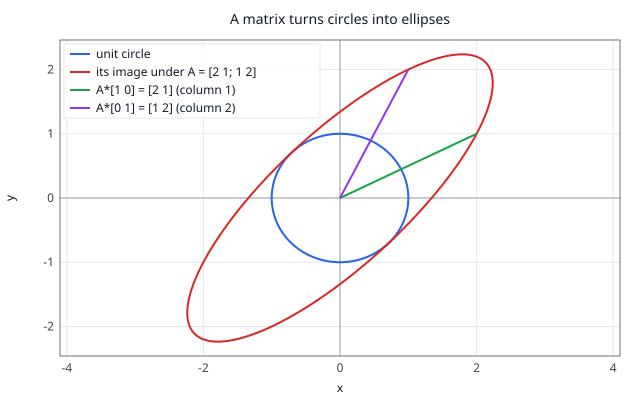

In [7]:
p = show(parametric(cos(t), sin(t), t, 0, 2*pi), parametric(w(1), w(2), t, 0, 2*pi), parametric(2*s, s, s, 0, 1), parametric(s, 2*s, s, 0, 1));
p = legend(p, "unit circle", "its image under A = [2 1; 1 2]", "A*[1 0] = [2 1] (column 1)", "A*[0 1] = [1 2] (column 2)");
labels(title(p, "A matrix turns circles into ellipses"), "x", "y")

The ellipse is stretched most along the diagonal $y = x$ and least along $y = -x$. Those two directions are special:
there $A$ only stretches without turning. They are the **eigenvectors** of lesson 2.

### Rotations

The matrix that rotates every vector by an angle $t$ has as columns the rotated unit arrows
$[\cos t\ \sin t]$ and $[-\sin t\ \cos t]$:

In [8]:
R = [cos(t), -sin(t); sin(t), cos(t)];
subs(R, t, pi/2)*[1; 0]

0
1

(Commas separate the entries here, because inside brackets a space followed by a minus sign starts a new entry.)

## 3. Multiplying matrices

Doing transformation $B$ and then $A$ is again a linear transformation, with matrix $AB$ (the **product**). Entry
$(i, j)$ of $AB$ is the dot product of row $i$ of $A$ with column $j$ of $B$. Rotating by $s$ and then by $t$ is rotating
by $s + t$, and the product shows the addition formulas of trigonometry:

In [9]:
Rs = [cos(s), -sin(s); sin(s), cos(s)];
expand(R*Rs)

cos(s)*cos(t)-sin(s)*sin(t)	-sin(s)*cos(t)-cos(s)*sin(t)
sin(s)*cos(t)+cos(s)*sin(t)	cos(s)*cos(t)-sin(s)*sin(t)

The top left entry is $\cos t\cos s - \sin t \sin s = \cos(t + s)$. As with the symmetries of the
[group theory path](../group-theory/README.md), order matters: $AB \ne BA$ in general.

In [10]:
B = [1 1; 0 1];
A*B
B*A

2	3
1	3
3	3
1	2

## 4. The determinant

The unit square (area 1) is turned into the parallelogram spanned by the two columns of $A$. Its area, with a sign, is
the **determinant**: for $[a\ b;\ c\ d]$ it is $ad - bc$. Every area is multiplied by $|\det A|$, so the ellipse above
has area $\pi\cdot|\det A| = 3\pi$:

In [11]:
det(A)
det([a b; c d])
det(R)
det([1 2; 2 4])

3

a*d-b*c

1
0

Rotations have determinant 1 (they keep areas). A negative determinant means the transformation flips the plane over,
like a mirror. A determinant of 0 means the plane is squashed onto a line: $[1\ 2;\ 2\ 4]$ sends everything onto
multiples of $[1\ 2]$, and there is no way back. Exactly the matrices with $\det A \ne 0$ have an **inverse**
$A^{-1}$ that undoes them:

In [12]:
inv(A)
inv(A)*A
inv([a b; c d])

2/3	-1/3
-1/3	2/3
1	0
0	1

d/(a*d-b*c)	b/(b*c-a*d)
c/(b*c-a*d)	a/(a*d-b*c)

## 5. Systems of linear equations

Two equations in two unknowns,

$$2x + y = 3, \qquad x + 3y = 5,$$

are one matrix equation $Ax = b$ with $A = [2\ 1;\ 1\ 3]$ and $b = [3;\ 5]$. Each equation is a line in the plane; the
solution is where they cross. The plot shows both lines, solved for $y$: $y = 3 - 2x$ and $y = (5 - x)/3$, with $x$
across and $y$ up:

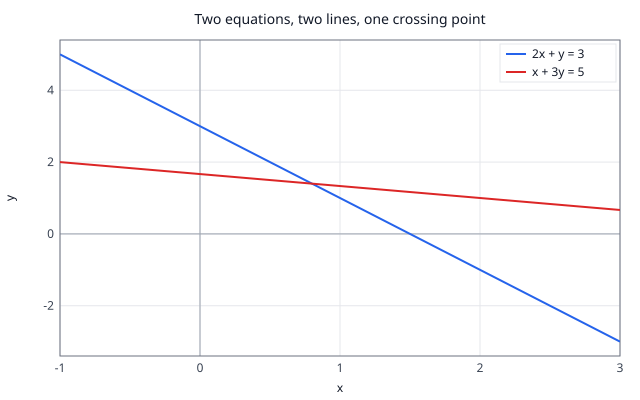

In [13]:
p = legend(plot(3 - 2*x, (5 - x)/3, x, -1, 3), "2x + y = 3", "x + 3y = 5");
labels(title(p, "Two equations, two lines, one crossing point"), "x", "y")

`A\b` solves $Ax = b$ ("divide by $A$ from the left"), and `solve` works with the equations directly:

In [14]:
[2 1; 1 3]\[3; 5]
solve([2*x + y == 3, x + 3*y == 5], [x, y])

4/5
7/5
4/5	7/5

The lines cross at $(4/5, 7/5)$.

### Row reduction

By hand you eliminate unknowns: subtract multiples of one equation from another. Done systematically on the table of
coefficients (with the right-hand side as a last column) this is **Gaussian elimination**, and the end result, where
each equation has one leading 1 and zeros above and below it, is the **reduced row echelon form**, `rref`. For

$$x + y + z = 6, \qquad x - y = 0, \qquad 2x + y - z = 0:$$

In [15]:
rref([1 1 1 6; 1 -1 0 0; 2 1 -1 0])

1	0	0	6/5
0	1	0	6/5
0	0	1	18/5

Read it row by row: $x = 6/5$, $y = 6/5$, $z = 18/5$.

### When there is no single answer

Three planes can also meet in a whole line, or not at all. Replace the third equation by $2x + 2y + 2z = 12$, which is
just twice the first:

In [16]:
M = [1 1 1; 1 -1 0; 2 2 2];
rref([M, [6; 0; 12]])
rank(M)
null(M)

1	0	1/2	3
0	1	1/2	3
0	0	0	0
2
-1/2
-1/2
1

The last row of the reduced form is all zeros: the third equation said nothing new. The **rank**, the number of
independent equations, is 2, less than the 3 unknowns, so one unknown is free. The rows read $x + z/2 = 3$ and
$y + z/2 = 3$: for any $z$ there is a solution. The **null space** `null(M)` holds the directions you can move in without
changing $Mx$: here multiples of $[-1/2\ \ {-1/2}\ \ 1]$. All solutions are one solution plus the null space:
$[3\ 3\ 0] + z\,[-1/2\ \ {-1/2}\ \ 1]$, a line in space.

If the right-hand side were $[6;\ 0;\ 13]$ instead, the last row would read $0 = 1$: no solution at all.

In [17]:
rref([M, [6; 0; 13]])

1	0	1/2	0
0	1	1/2	0
0	0	0	1

## Summary

* Vectors add head to tail; `norm` is the length, `dot` measures angles ($u\cdot v = 0$: perpendicular), `cross` in 3D.
* A matrix is a transformation; its columns are the images of the unit vectors. `A*x` applies it.
* The product $AB$ is "first $B$, then $A$"; not commutative.
* `det(A)` is the area scaling factor; $\det A = 0$ means no inverse. `inv(A)`.
* Systems $Ax = b$: `A\b`, `solve`, `rref`; `rank` counts independent equations, `null` gives the free directions.

**Try it:** find the matrix that reflects the plane in the line $y = x$ (where do $[1\ 0]$ and $[0\ 1]$ go?) and check
that its determinant is $-1$. Which matrix rotates by $90^\circ$, and what is its square? Find all solutions of
$x + 2y + 3z = 0$, $4x + 5y + 6z = 0$, $7x + 8y + 9z = 0$.

Next: [Eigenvalues](02-eigenvalues.ipynb): the directions a matrix only stretches.

## Sources

1. G. Strang, *Introduction to Linear Algebra*, 5th ed., Wellesley-Cambridge Press (2016). Chapters 1–3.
2. S. Axler, *Linear Algebra Done Right*, 4th ed., Springer (2024), open access. Chapters 1–3.
3. C. F. Gauss, *Theoria motus corporum coelestium* (1809): elimination for least-squares orbit fitting.